# Sri Lanka Daily Rainfall Prediction: Ensemble Learning Comparison

AI tools used: this code was generated with AI assistance (Antigravity / Claude). I reviewed it and can explain it.

### Credits & AI Usage Declaration
- **Code & Frontend Declaration:** Code implementation and the Streamlit dashboard frontend were developed with AI assistance as permitted by the module guidelines; dataset validation, feature selection, model comparison, and results interpretation were performed and verified by me (Dulshan).
- **Dataset Credit:** Sri Lanka Weather Dataset by `rasulmah` on Kaggle (https://www.kaggle.com/datasets/rasulmah/sri-lanka-weather-dataset), collected via the Open-Meteo Historical Weather API (https://open-meteo.com/) for 30 Sri Lankan cities (2010-2023).
- **Libraries Credit:** `scikit-learn`, `XGBoost`, `LightGBM`, `CatBoost`, `pandas`, `matplotlib`, `seaborn`, `Plotly`, and `Streamlit`.

---

**Objective:** Predict daily rainfall (`rain_sum` in mm) across five representative Sri Lankan cities using meteorological, geographic, and lag features, and compare **Bagging (Random Forest)**, **Boosting (XGBoost, LightGBM, CatBoost)**, and **Stacking (Ridge meta-learner)** against a **Naive Persistence Baseline** on a chronological hold-out split.

## 1. Data Loading & Initial Inspection

We load `SriLanka_Weather_Dataset.csv`, and inspect its schema, missing values, date coverage, and city distribution. Because the full dataset has `147,480` rows across 30 equally complete cities (`4,916` rows each, `0` missing values), we filter to **5 major cities** spanning Sri Lanka's distinct climatic zones: **Colombo** (west coast wet zone), **Kandy** (central highlands), **Ratnapura** (inland wet zone), **Galle** (southwest coast), and **Jaffna** (northern dry zone), yielding `24,580` daily records.

In [1]:
import os
os.makedirs("models", exist_ok=True)

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Load raw dataset
raw_df = pd.read_csv("SriLanka_Weather_Dataset.csv")
print(f"Raw shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Unique cities ({raw_df['city'].nunique()}): {sorted(raw_df['city'].unique())}")
print(f"Date range: {raw_df['time'].min()} to {raw_df['time'].max()}")
print(f"Total missing values across all columns: {int(raw_df.isna().sum().sum())}")
print("\nColumn dtypes:")
print(raw_df.dtypes)

# Filter to 5 major climatic-zone cities
SELECTED_CITIES = ["Colombo", "Kandy", "Ratnapura", "Galle", "Jaffna"]
df = raw_df[raw_df["city"].isin(SELECTED_CITIES)].copy()
print(f"\nFiltered shape ({len(SELECTED_CITIES)} cities): {df.shape[0]:,} rows x {df.shape[1]} columns")
print(df["city"].value_counts())
df.head()

Raw shape: 147,480 rows x 24 columns
Unique cities (30): ['Athurugiriya', 'Badulla', 'Bentota', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Hatton', 'Jaffna', 'Kalmunai', 'Kalutara', 'Kandy', 'Kesbewa', 'Kolonnawa', 'Kurunegala', 'Mabole', 'Maharagama', 'Mannar', 'Matale', 'Matara', 'Moratuwa', 'Mount Lavinia', 'Negombo', 'Oruwala', 'Pothuhera', 'Puttalam', 'Ratnapura', 'Sri Jayewardenepura Kotte', 'Trincomalee', 'Weligama']
Date range: 2010-01-01 to 2023-06-17
Total missing values across all columns: 0

Column dtypes:
time                              str
weathercode                     int64
temperature_2m_max            float64
temperature_2m_min            float64
temperature_2m_mean           float64
apparent_temperature_max      float64
apparent_temperature_min      float64
apparent_temperature_mean     float64
sunrise                           str
sunset                            str
shortwave_radiation_sum       float64
precipitation_sum             float64
rain_sum         

,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,country,city
0,2010-01-01,2,30.0,22.7,26.1,34.4,25.2,29.2,2010-01-01T00:52,2010-01-01T12:35,20.92,0.0,0.0,0.0,0.0,11.7,27.4,20,4.58,7.0,79.899994,16.0,Sri Lanka,Colombo
1,2010-01-02,51,29.9,23.5,26.2,33.8,26.2,29.8,2010-01-02T00:52,2010-01-02T12:36,17.71,0.1,0.1,0.0,1.0,13.0,27.0,24,3.84,7.0,79.899994,16.0,Sri Lanka,Colombo
2,2010-01-03,51,29.5,23.2,26.0,34.3,26.3,29.9,2010-01-03T00:53,2010-01-03T12:36,17.76,0.6,0.6,0.0,3.0,12.3,27.4,16,3.65,7.0,79.899994,16.0,Sri Lanka,Colombo
3,2010-01-04,2,28.9,21.9,25.3,31.6,23.4,27.8,2010-01-04T00:53,2010-01-04T12:37,16.50,0.0,0.0,0.0,0.0,17.0,34.6,356,3.79,7.0,79.899994,16.0,Sri Lanka,Colombo
4,2010-01-05,1,28.1,21.3,24.5,30.1,23.1,26.1,2010-01-05T00:53,2010-01-05T12:37,23.61,0.0,0.0,0.0,0.0,18.7,37.1,355,4.97,7.0,79.899994,16.0,Sri Lanka,Colombo


## 2. Data Cleaning & Target Leakage Removal

We parse `time` as a `datetime` column, sort chronologically by `['city', 'time']`, and derive `daylight_duration` (in hours) from `sunset` and `sunrise`. To prevent target leakage and remove redundant fields, we drop:
- `precipitation_sum` and `precipitation_hours` (direct components/co-measurements of daily rainfall)
- `weathercode` (WMO weather code encoded from observed rain/weather on that day)
- `snowfall_sum` (always `0.0` in tropical Sri Lanka)
- `sunrise`, `sunset` (replaced by `daylight_duration`), and `country` (constant `'Sri Lanka'`).

In [2]:
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values(["city", "time"]).reset_index(drop=True)

# Compute daylight duration in hours
sunrise_dt = pd.to_datetime(df["sunrise"])
sunset_dt = pd.to_datetime(df["sunset"])
df["daylight_duration"] = (sunset_dt - sunrise_dt).dt.total_seconds() / 3600.0

# Drop leaky or non-informative columns
drop_cols = [
    "precipitation_sum",
    "precipitation_hours",
    "snowfall_sum",
    "weathercode",
    "sunrise",
    "sunset",
    "country",
]
df = df.drop(columns=drop_cols)

print(f"Cleaned shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Remaining columns:", list(df.columns))
print("Missing values:", int(df.isna().sum().sum()))
df.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Cleaned shape: 24,580 rows x 18 columns
Remaining columns: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'apparent_temperature_min', 'apparent_temperature_mean', 'shortwave_radiation_sum', 'rain_sum', 'windspeed_10m_max', 'windgusts_10m_max', 'winddirection_10m_dominant', 'et0_fao_evapotranspiration', 'latitude', 'longitude', 'elevation', 'city', 'daylight_duration']
Missing values: 0


,mean,std,min,50%,max
time,2016-09-23 12:00:00,NaN,2010-01-01 00:00:00,2016-09-23 12:00:00,2023-06-17 00:00:00
temperature_2m_max,28.951282,1.864534,19.4,29.0,36.1
temperature_2m_min,23.764459,2.362868,14.2,24.1,30.0
temperature_2m_mean,26.053063,1.88162,18.0,26.2,31.3
apparent_temperature_max,33.824024,2.965666,21.8,34.0,42.3
apparent_temperature_min,27.363312,2.868673,12.9,27.9,34.7
apparent_temperature_mean,30.065594,2.481624,19.8,30.5,36.8
shortwave_radiation_sum,18.715441,4.242858,1.44,19.41,28.12
rain_sum,6.069292,10.570139,0.0,2.6,259.5
windspeed_10m_max,16.478413,7.859243,3.1,15.25,50.2


## 3. Exploratory Data Analysis (EDA)

We explore the distribution of daily rainfall, seasonal monsoon patterns across months, regional differences across the five cities, and linear correlations with our candidate features.

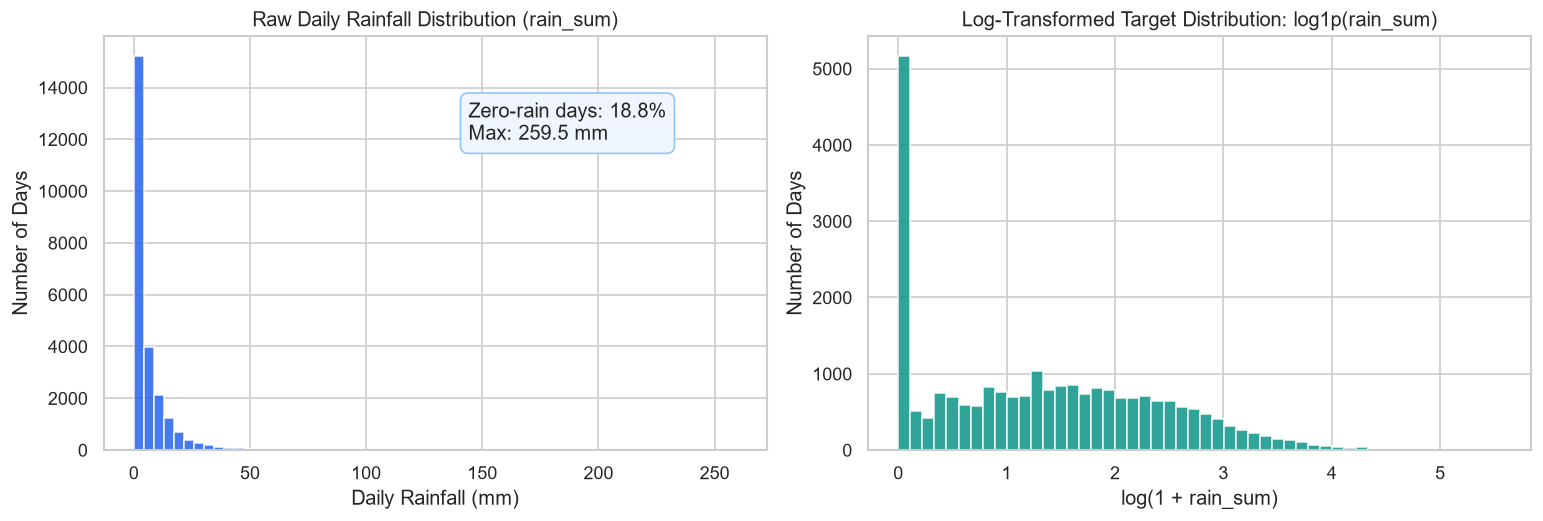

In [3]:
# Figure 1: Raw vs. log1p-transformed daily rainfall distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df["rain_sum"], bins=60, color="#2563eb", edgecolor="white", alpha=0.85)
axes[0].set_title("Raw Daily Rainfall Distribution (rain_sum)")
axes[0].set_xlabel("Daily Rainfall (mm)")
axes[0].set_ylabel("Number of Days")

zero_pct = (df["rain_sum"] == 0).mean() * 100
axes[0].annotate(
    f"Zero-rain days: {zero_pct:.1f}%\nMax: {df['rain_sum'].max():.1f} mm",
    xy=(0.55, 0.75), xycoords="axes fraction",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#eff6ff", edgecolor="#93c5fd")
)

axes[1].hist(np.log1p(df["rain_sum"]), bins=50, color="#0d9488", edgecolor="white", alpha=0.85)
axes[1].set_title("Log-Transformed Target Distribution: log1p(rain_sum)")
axes[1].set_xlabel("log(1 + rain_sum)")
axes[1].set_ylabel("Number of Days")

plt.tight_layout()
plt.show()

**Interpretation (Figure 1):** Raw `rain_sum` is strongly right-skewed with a large spike at zero (dry days) and a long tail of intense monsoon downpours. Applying `log1p(rain_sum)` compresses extreme values into a better-behaved distribution for tree-based regression while preserving monotonicity.

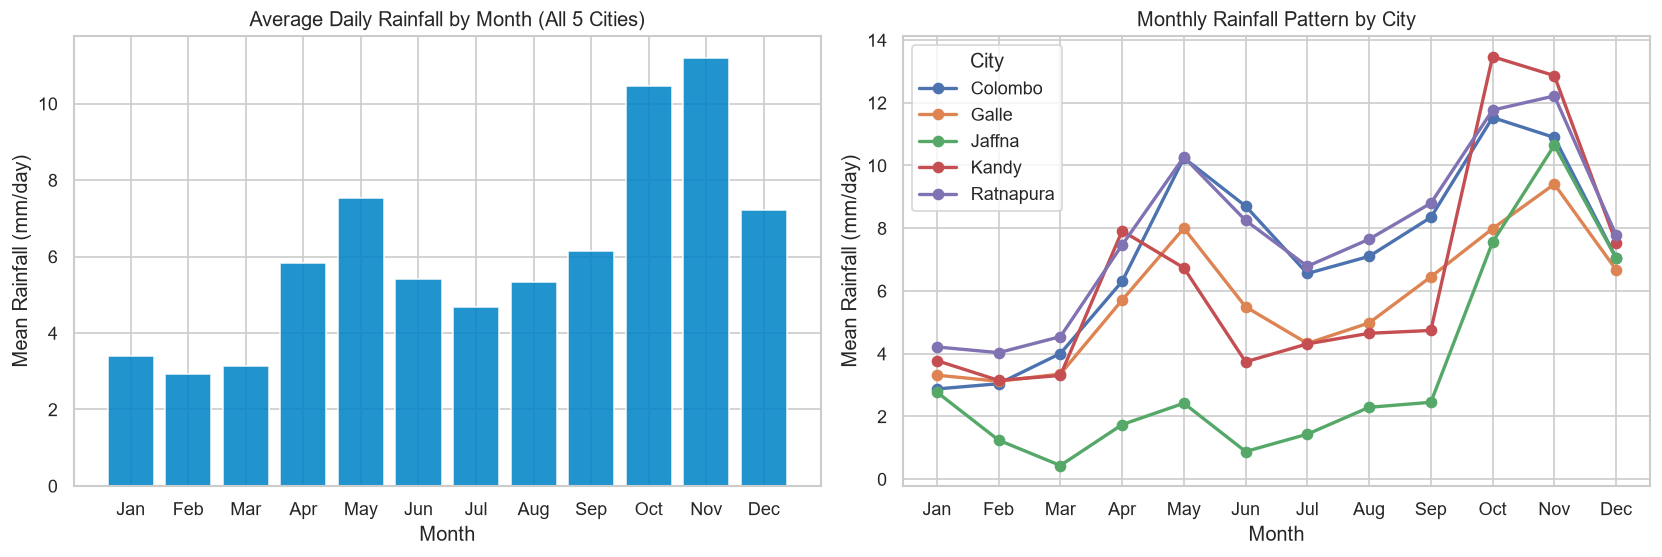

In [4]:
# Figure 2: Monthly rainfall pattern overall and by city
eda_df = df.copy()
eda_df["month"] = eda_df["time"].dt.month
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

monthly_overall = eda_df.groupby("month")["rain_sum"].mean()
axes[0].bar(monthly_overall.index, monthly_overall.values, color="#0284c7", alpha=0.88)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].set_title("Average Daily Rainfall by Month (All 5 Cities)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Rainfall (mm/day)")

monthly_city = eda_df.groupby(["month", "city"])["rain_sum"].mean().unstack()
monthly_city.plot(ax=axes[1], marker="o", linewidth=2)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_title("Monthly Rainfall Pattern by City")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean Rainfall (mm/day)")
axes[1].legend(title="City", frameon=True)

plt.tight_layout()
plt.show()

**Interpretation (Figure 2):** Sri Lanka exhibits clear bimodal monsoon seasonality: Southwest Monsoon peaks in May and October-November across Colombo, Galle, Ratnapura, and Kandy, whereas Jaffna in the northern dry zone receives most of its rain during the Northeast Monsoon (October-December).

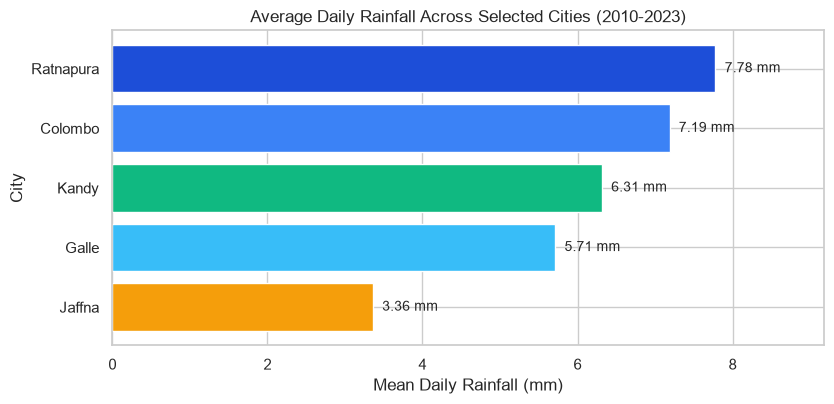

In [5]:
# Figure 3: Average daily rainfall by city
city_rain = df.groupby("city")["rain_sum"].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.barh(city_rain.index, city_rain.values, color=["#f59e0b", "#38bdf8", "#10b981", "#3b82f6", "#1d4ed8"])
ax.set_title("Average Daily Rainfall Across Selected Cities (2010-2023)")
ax.set_xlabel("Mean Daily Rainfall (mm)")
ax.set_ylabel("City")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.12, bar.get_y() + bar.get_height() / 2, f"{w:.2f} mm", va="center", fontsize=10)
ax.set_xlim(0, city_rain.max() * 1.18)

plt.tight_layout()
plt.show()

**Interpretation (Figure 3):** Ratnapura (7.78 mm/day) and Colombo (7.19 mm/day) are the wettest cities, followed by highland Kandy (6.31 mm/day) and coastal Galle (5.71 mm/day), while Jaffna (3.36 mm/day) receives less than half the daily average of Ratnapura.

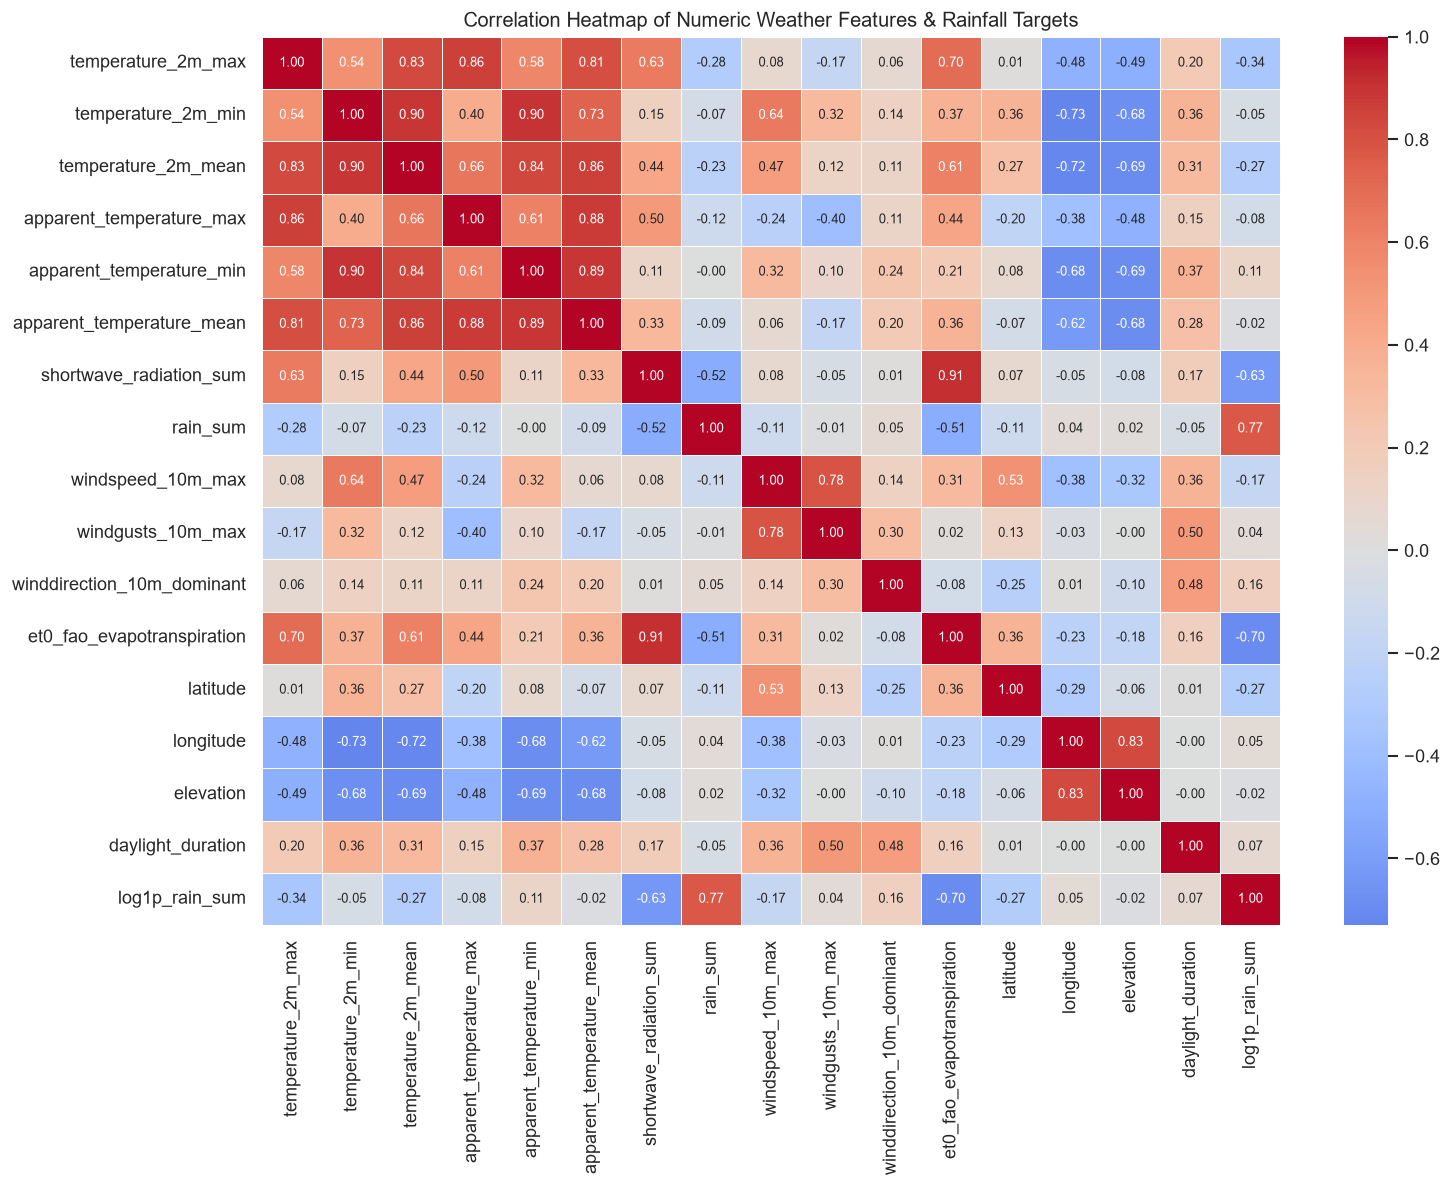

In [6]:
# Figure 4: Correlation heatmap of numeric features with rain_sum and log1p(rain_sum)
corr_df = df.select_dtypes(include=[np.number]).copy()
corr_df["log1p_rain_sum"] = np.log1p(corr_df["rain_sum"])
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
    linewidths=0.4,
    ax=ax,
)
ax.set_title("Correlation Heatmap of Numeric Weather Features & Rainfall Targets")
plt.tight_layout()
plt.show()

**Interpretation (Figure 4):** Cloud- and energy-related variables such as `shortwave_radiation_sum`, `et0_fao_evapotranspiration`, and `temperature_2m_max` correlate negatively with rainfall (rainy days have heavier cloud cover and lower solar radiation/evapotranspiration), while wind gusts and minimum temperature show positive associations.

## 4. Feature Engineering & Chronological Train/Test Split

To capture seasonality and short-term persistence without data leakage:
1. Extract calendar features `month` and `day_of_year`.
2. Compute per-city lag-1 features (`rain_sum_lag1`, `temp_mean_lag1`) strictly using `groupby('city').shift(1)` on chronologically sorted data, then drop the single initial `NaN` day per city (`24,575` rows remaining).
3. Map `city` alphabetically to `city_encoded` (`0` to `4`).
4. Train on `y_log = np.log1p(rain_sum)` and evaluate all models on the original **millimeter (mm)** scale via `np.clip(np.expm1(y_pred_log), 0, None)`.
5. Split chronologically (no random shuffling): **Train** = `time <= '2021-06-17'` (`20,925` rows) and **Test** = last 2 full years `time > '2021-06-17'` (`3,650` rows).

In [7]:
# Ensure chronological order per city before lag calculation
df = df.sort_values(["city", "time"]).reset_index(drop=True)

df["month"] = df["time"].dt.month
df["day_of_year"] = df["time"].dt.dayofyear
df["rain_sum_lag1"] = df.groupby("city")["rain_sum"].shift(1)
df["temp_mean_lag1"] = df.groupby("city")["temperature_2m_mean"].shift(1)

# Drop the 1st row per city (5 rows) where lag-1 is NaN
df = df.dropna(subset=["rain_sum_lag1", "temp_mean_lag1"]).reset_index(drop=True)

city_mapping = {"Colombo": 0, "Galle": 1, "Jaffna": 2, "Kandy": 3, "Ratnapura": 4}
df["city_encoded"] = df["city"].map(city_mapping)

feature_cols = [
    "month",
    "day_of_year",
    "city_encoded",
    "latitude",
    "longitude",
    "elevation",
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "apparent_temperature_max",
    "apparent_temperature_min",
    "apparent_temperature_mean",
    "shortwave_radiation_sum",
    "windspeed_10m_max",
    "windgusts_10m_max",
    "winddirection_10m_dominant",
    "et0_fao_evapotranspiration",
    "daylight_duration",
    "rain_sum_lag1",
    "temp_mean_lag1",
]

# Sort globally by ['time', 'city'] for chronological CV and train/test split
df = df.sort_values(["time", "city"]).reset_index(drop=True)

split_date = pd.Timestamp("2021-06-17")
train_mask = df["time"] <= split_date
test_mask = df["time"] > split_date

train_df = df.loc[train_mask].copy()
test_df = df.loc[test_mask].copy()

X_train = train_df[feature_cols]
y_train_log = np.log1p(train_df["rain_sum"].values)

X_test = test_df[feature_cols]
y_test_mm = test_df["rain_sum"].values

print(f"Total rows after lag-1 drop: {len(df):,}")
print(f"Feature count: {len(feature_cols)}")
print(f"Train set: {len(train_df):,} rows ({train_df['time'].min().date()} to {train_df['time'].max().date()})")
print(f"Test set : {len(test_df):,} rows ({test_df['time'].min().date()} to {test_df['time'].max().date()})")

Total rows after lag-1 drop: 24,575
Feature count: 20
Train set: 20,925 rows (2010-01-02 to 2021-06-17)
Test set : 3,650 rows (2021-06-18 to 2023-06-17)


## 5. Model Training & Hyperparameter Tuning

We evaluate a **Naive Persistence Baseline** (predicting today's rain equals yesterday's `rain_sum_lag1`) alongside four tree-ensemble families tuned via `RandomizedSearchCV` (`n_iter=3`, `cv=TimeSeriesSplit(n_splits=3)`, optimizing `neg_root_mean_squared_error` on `log1p(rain_sum)`):
- **Bagging:** `RandomForestRegressor`
- **Boosting:** `XGBRegressor`, `LGBMRegressor`, and `CatBoostRegressor`

In [8]:
def to_mm(y_pred_log):
    return np.clip(np.expm1(y_pred_log), 0.0, None)

def evaluate_mm(model_name, category, y_true, y_pred):
    return {
        "Model": model_name,
        "Category": category,
        "RMSE (mm)": round(float(root_mean_squared_error(y_true, y_pred)), 4),
        "MAE (mm)": round(float(mean_absolute_error(y_true, y_pred)), 4),
        "R²": round(float(r2_score(y_true, y_pred)), 4),
    }

results = []
best_params = {}
test_preds = {}

# 1. Naive Baseline (yesterday's rain)
y_pred_naive = test_df["rain_sum_lag1"].values
test_preds["pred_naive"] = y_pred_naive
results.append(evaluate_mm("Naive Baseline (Lag-1)", "Baseline", y_test_mm, y_pred_naive))
print("Naive Baseline:", results[-1])

tscv = TimeSeriesSplit(n_splits=3)

# 2. Bagging: Random Forest
rf_base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)
rf_param_dist = {
    "n_estimators": [100, 150],
    "max_depth": [12, 16, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.6, 0.8],
}
rf_search = RandomizedSearchCV(
    rf_base, rf_param_dist, n_iter=3, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1
)
rf_search.fit(X_train, y_train_log)
best_rf = rf_search.best_estimator_
best_params["Random Forest"] = rf_search.best_params_
y_pred_rf = to_mm(best_rf.predict(X_test))
test_preds["pred_rf"] = y_pred_rf
results.append(evaluate_mm("Random Forest", "Bagging", y_test_mm, y_pred_rf))
print("Random Forest best params:", rf_search.best_params_)
print("Random Forest:", results[-1])

# 3. Boosting: XGBoost
xgb_base = XGBRegressor(
    random_state=RANDOM_STATE, objective="reg:squarederror", tree_method="hist", n_jobs=1
)
xgb_param_dist = {
    "n_estimators": [150, 250],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.75, 0.85, 1.0],
    "colsample_bytree": [0.75, 0.85, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [1.0, 2.0, 5.0],
}
xgb_search = RandomizedSearchCV(
    xgb_base, xgb_param_dist, n_iter=3, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1
)
xgb_search.fit(X_train, y_train_log)
best_xgb = xgb_search.best_estimator_
best_params["XGBoost"] = xgb_search.best_params_
y_pred_xgb = to_mm(best_xgb.predict(X_test))
test_preds["pred_xgb"] = y_pred_xgb
results.append(evaluate_mm("XGBoost", "Boosting", y_test_mm, y_pred_xgb))
print("XGBoost best params:", xgb_search.best_params_)
print("XGBoost:", results[-1])

# 4. Boosting: LightGBM
lgbm_base = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
lgbm_param_dist = {
    "n_estimators": [150, 250],
    "num_leaves": [31, 50, 70],
    "max_depth": [-1, 6, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.75, 0.85, 1.0],
    "colsample_bytree": [0.75, 0.85, 1.0],
    "min_child_samples": [20, 40, 60],
}
lgbm_search = RandomizedSearchCV(
    lgbm_base, lgbm_param_dist, n_iter=3, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1
)
lgbm_search.fit(X_train, y_train_log)
best_lgbm = lgbm_search.best_estimator_
best_params["LightGBM"] = lgbm_search.best_params_
y_pred_lgbm = to_mm(best_lgbm.predict(X_test))
test_preds["pred_lgbm"] = y_pred_lgbm
results.append(evaluate_mm("LightGBM", "Boosting", y_test_mm, y_pred_lgbm))
print("LightGBM best params:", lgbm_search.best_params_)
print("LightGBM:", results[-1])

# 5. Boosting: CatBoost
cb_base = CatBoostRegressor(random_seed=RANDOM_STATE, verbose=0, thread_count=1)
cb_param_dist = {
    "iterations": [200, 300],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5, 7],
}
cb_search = RandomizedSearchCV(
    cb_base, cb_param_dist, n_iter=3, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1
)
cb_search.fit(X_train, y_train_log)
best_cb = cb_search.best_estimator_
best_params["CatBoost"] = cb_search.best_params_
y_pred_cb = to_mm(best_cb.predict(X_test))
test_preds["pred_catboost"] = y_pred_cb
results.append(evaluate_mm("CatBoost", "Boosting", y_test_mm, y_pred_cb))
print("CatBoost best params:", cb_search.best_params_)
print("CatBoost:", results[-1])

Naive Baseline: {'Model': 'Naive Baseline (Lag-1)', 'Category': 'Baseline', 'RMSE (mm)': 9.8039, 'MAE (mm)': 4.8907, 'R²': -0.1935}
Random Forest best params: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': None}
Random Forest: {'Model': 'Random Forest', 'Category': 'Bagging', 'RMSE (mm)': 6.4423, 'MAE (mm)': 2.9975, 'R²': 0.4846}
XGBoost best params: {'subsample': 0.85, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 250, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
XGBoost: {'Model': 'XGBoost', 'Category': 'Boosting', 'RMSE (mm)': 6.0731, 'MAE (mm)': 2.8186, 'R²': 0.542}
LightGBM best params: {'subsample': 0.85, 'num_leaves': 70, 'n_estimators': 250, 'min_child_samples': 60, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
LightGBM: {'Model': 'LightGBM', 'Category': 'Boosting', 'RMSE (mm)': 6.0535, 'MAE (mm)': 2.82, 'R²': 0.545}
CatBoost best params: {'learning_rate': 0.1, 'l2_leaf_reg': 1,

## 6. Stacking Ensemble (`StackingRegressor`)

We combine all four tree ensembles (**Random Forest** for Bagging, and **XGBoost, LightGBM, CatBoost** for Boosting) into a `StackingRegressor` using contiguous 5-fold out-of-fold predictions (`KFold(n_splits=5, shuffle=False)`) and a regularized `RidgeCV` meta-learner.

In [9]:
stacking_model = StackingRegressor(
    estimators=[
        ("rf", best_rf),
        ("xgb", best_xgb),
        ("lgbm", best_lgbm),
        ("catboost", best_cb),
    ],
    final_estimator=RidgeCV(alphas=np.logspace(-2, 3, 20)),
    cv=KFold(n_splits=5, shuffle=False),
    n_jobs=1,
)
stacking_model.fit(X_train, y_train_log)
y_pred_stack = to_mm(stacking_model.predict(X_test))
test_preds["pred_stacking"] = y_pred_stack
results.append(evaluate_mm("Stacking Ensemble", "Stacking", y_test_mm, y_pred_stack))

meta_coefs = dict(zip(["RF", "XGBoost", "LightGBM", "CatBoost"], np.round(stacking_model.final_estimator_.coef_, 4)))
print("RidgeCV alpha:", round(float(stacking_model.final_estimator_.alpha_), 4))
print("Meta-learner weights:", meta_coefs)
print("Stacking Ensemble:", results[-1])

RidgeCV alpha: 7.8476
Meta-learner weights: {'RF': np.float64(-0.2342), 'XGBoost': np.float64(0.3966), 'LightGBM': np.float64(0.3361), 'CatBoost': np.float64(0.5081)}
Stacking Ensemble: {'Model': 'Stacking Ensemble', 'Category': 'Stacking', 'RMSE (mm)': 6.0326, 'MAE (mm)': 2.7983, 'R²': 0.5481}


## 7. Results Comparison, Feature Importance & Artifact Saving

We compile all test-set metrics on the original millimeter scale, visualize model performance and top feature importances, and serialize the trained models, metadata, and test-set predictions to `models/` for the Streamlit dashboard.

,Model,Category,RMSE (mm),MAE (mm),R²
0,Stacking Ensemble,Stacking,6.0326,2.7983,0.5481
1,LightGBM,Boosting,6.0535,2.8200,0.5450
2,XGBoost,Boosting,6.0731,2.8186,0.5420
3,CatBoost,Boosting,6.0980,2.8238,0.5382
4,Random Forest,Bagging,6.4423,2.9975,0.4846
5,Naive Baseline (Lag-1),Baseline,9.8039,4.8907,-0.1935


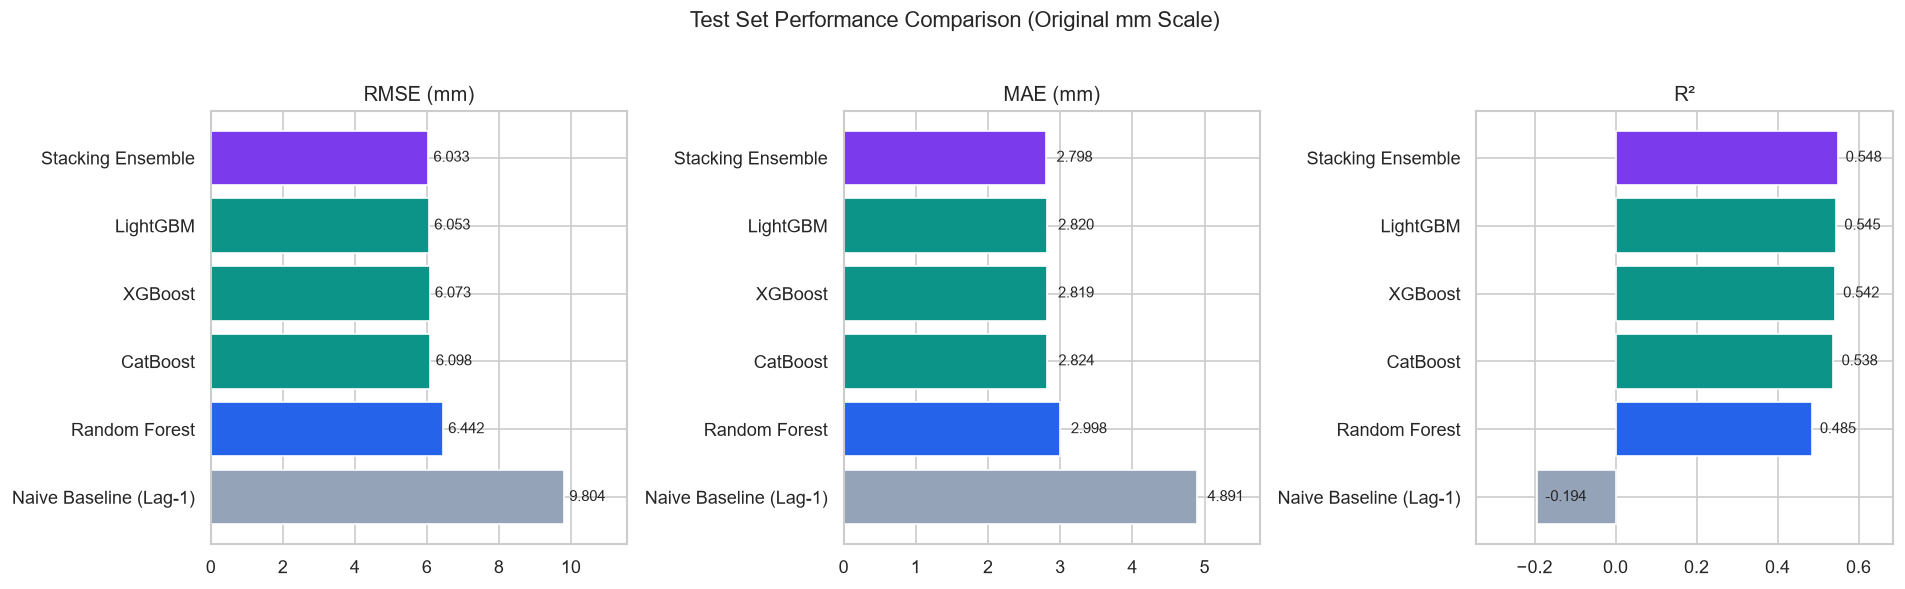

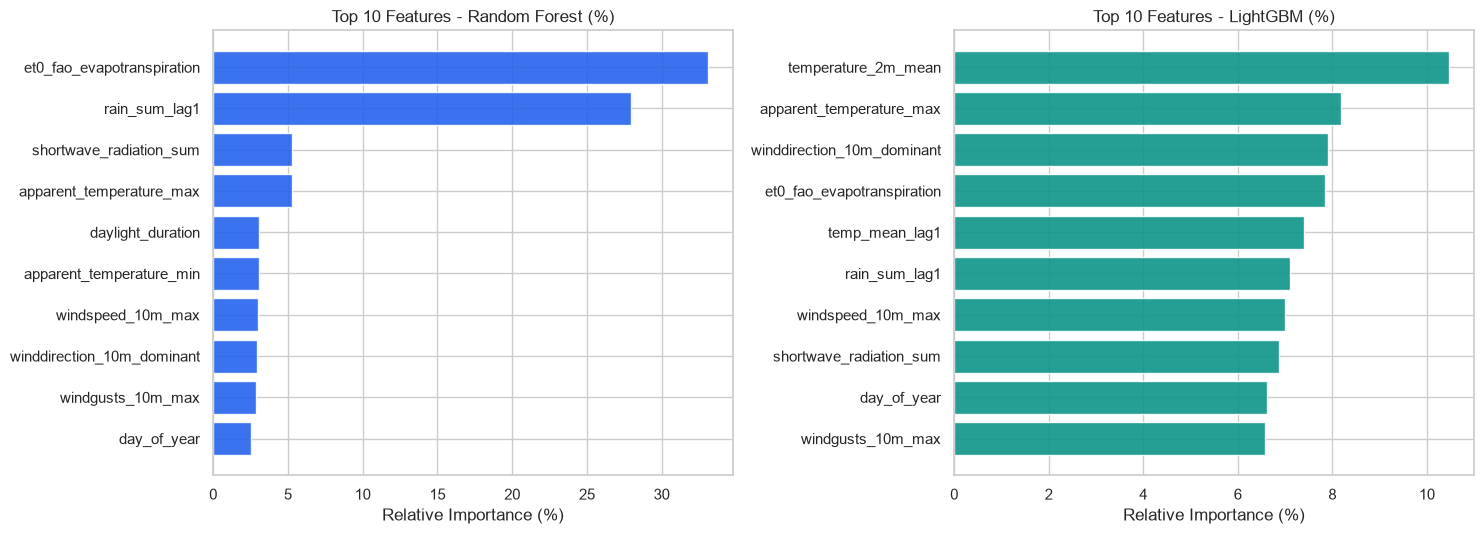

In [10]:
results_df = pd.DataFrame(results).sort_values("RMSE (mm)", ascending=True).reset_index(drop=True)
display(results_df)

# Comparison Bar Charts: RMSE, MAE, R2
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
palette = {"Baseline": "#94a3b8", "Bagging": "#2563eb", "Boosting": "#0d9488", "Stacking": "#7c3aed"}
colors = [palette[c] for c in results_df["Category"]]

for ax, metric in zip(axes, ["RMSE (mm)", "MAE (mm)", "R²"]):
    bars = ax.barh(results_df["Model"], results_df[metric], color=colors)
    ax.invert_yaxis()
    ax.set_title(metric)
    for b in bars:
        val = b.get_width()
        ax.text(val + (0.02 if metric == "R²" else 0.15), b.get_y() + b.get_height() / 2, f"{val:.3f}", va="center", fontsize=9)
    if metric != "R²":
        ax.set_xlim(0, results_df[metric].max() * 1.18)
    else:
        ax.set_xlim(min(0, results_df[metric].min() - 0.15), results_df[metric].max() * 1.25)

plt.suptitle("Test Set Performance Comparison (Original mm Scale)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Feature Importances (normalized to sum to 100%)
def norm_imp(vals):
    arr = np.asarray(vals, dtype=float)
    return (arr / arr.sum()) * 100.0 if arr.sum() > 0 else arr

fi_df = pd.DataFrame({
    "feature": feature_cols,
    "Random Forest": norm_imp(best_rf.feature_importances_),
    "XGBoost": norm_imp(best_xgb.feature_importances_),
    "LightGBM": norm_imp(best_lgbm.feature_importances_),
    "CatBoost": norm_imp(best_cb.get_feature_importance()),
})

# Identify best Boosting model by RMSE
boosting_rows = results_df[results_df["Category"] == "Boosting"]
best_boosting_name = boosting_rows.iloc[0]["Model"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, mname, col in zip(axes, ["Random Forest", best_boosting_name], ["#2563eb", "#0d9488"]):
    top10 = fi_df[["feature", mname]].sort_values(mname, ascending=True).tail(10)
    ax.barh(top10["feature"], top10[mname], color=col, alpha=0.9)
    ax.set_title(f"Top 10 Features - {mname} (%)")
    ax.set_xlabel("Relative Importance (%)")

plt.tight_layout()
plt.show()

In [11]:
# Save all artifacts to models/
joblib.dump(best_rf, "models/rf_model.joblib")
joblib.dump(best_xgb, "models/xgb_model.joblib")
joblib.dump(best_lgbm, "models/lgbm_model.joblib")
joblib.dump(best_cb, "models/catboost_model.joblib")
joblib.dump(stacking_model, "models/stacking_model.joblib")

joblib.dump(feature_cols, "models/feature_cols.joblib")
joblib.dump(city_mapping, "models/city_mapping.joblib")
joblib.dump(results_df, "models/results_df.joblib")
results_df.to_csv("models/results_table.csv", index=False)
joblib.dump(best_params, "models/best_params.joblib")
joblib.dump(fi_df, "models/feature_importances.joblib")

# Build rich city metadata for Streamlit Live Prediction defaults & presets
city_metadata = {}
slider_features = [c for c in feature_cols if c not in ("month", "day_of_year", "city_encoded", "latitude", "longitude", "elevation")]
for city in SELECTED_CITIES:
    sub = df[df["city"] == city]
    monthly_med = sub.groupby("month")[slider_features].median().round(2).to_dict(orient="index")
    city_metadata[city] = {
        "city_encoded": int(city_mapping[city]),
        "latitude": float(sub["latitude"].iloc[0]),
        "longitude": float(sub["longitude"].iloc[0]),
        "elevation": float(sub["elevation"].iloc[0]),
        "overall_medians": sub[slider_features].median().round(2).to_dict(),
        "monthly_medians": monthly_med,
        "feature_bounds": {
            col: {
                "min": round(float(df[col].quantile(0.005)), 2),
                "max": round(float(df[col].quantile(0.995)), 2),
            }
            for col in slider_features
        },
    }
joblib.dump(city_metadata, "models/city_metadata.joblib")

# Save cleaned dataset with split & test predictions for dashboard
processed_df = df.copy()
processed_df["split"] = np.where(train_mask, "train", "test")
for col_name, preds in test_preds.items():
    processed_df[col_name] = np.nan
    processed_df.loc[test_mask, col_name] = np.round(preds, 4)

processed_df.to_csv("models/processed_weather.csv", index=False)
print("Saved all artifacts in models/:", sorted(os.listdir("models")))

Saved all artifacts in models/: ['best_params.joblib', 'catboost_model.joblib', 'city_mapping.joblib', 'city_metadata.joblib', 'feature_cols.joblib', 'feature_importances.joblib', 'lgbm_model.joblib', 'processed_weather.csv', 'results_df.joblib', 'results_table.csv', 'rf_model.joblib', 'stacking_model.joblib', 'xgb_model.joblib']


## 8. Critical Analysis

Across the two-year chronological hold-out set (`2021-06-18` to `2023-06-17`, `3,650` daily records), **Stacking Ensemble** (Stacking) achieved the strongest generalization with **RMSE = 6.0326 mm**, **MAE = 2.7983 mm**, and **R² = 0.5481**, closely followed by **LightGBM** (RMSE = 6.0535 mm, MAE = 2.8200 mm, R² = 0.5450) and vastly outperforming the **Naive Persistence Baseline** (RMSE = 9.8039 mm, MAE = 4.8907 mm, R² = -0.1935). Between families, **Random Forest** (Bagging; RMSE = 6.4423 mm, R² = 0.4846) reduces variance across bootstrap trees, whereas **Boosting** (led by **LightGBM** at RMSE = 6.0535 mm, R² = 0.5450) iteratively corrects residual errors to capture sharp convective rainfall thresholds. Stacking (`RidgeCV`) blends these complementary bias-variance profiles.

Feature importances consistently highlight `et0_fao_evapotranspiration`, `rain_sum_lag1`, `apparent_temperature_max`, `temperature_2m_mean`, and `shortwave_radiation_sum` as dominant predictors: monsoon cloud cover suppresses solar radiation and evapotranspiration while driving wind gusts and day-to-day moisture persistence. Key limitations include zero-inflation (~18.8% dry days) paired with extreme monsoon spikes (>100 mm), causing `log1p` squared-error regression to underestimate rare downpours, plus missing upper-air pressure and relative humidity predictors. Unlike deep neural networks suited for unstructured images or text, bagged and boosted tree ensembles excel on heterogeneous tabular weather data with mixed scales and non-linear interactions.